<a href="https://colab.research.google.com/github/poojasingri15/statistics/blob/main/Program2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import pandas as pd

np.random.seed(42)

def print_distribution_stats(name, data, dist):
  print(f"\n--- {name} ---")
  print(f" Theoretical Mean    : {dist.mean():.4f}")
  print(f" Simulated Mean      : {np.mean(data):.4f}")
  print(f" Theoretical Variance: {dist.var():.4f}")
  print(f" Simulated Variance  : {np.var(data):.4f}")
  print(f" Theoretical Std Dev : {dist.std():.4f}")
  print(f" E[X2] (2nd Moment)  : {dist.moment(2):.4f}")
  print(f" Skewness            : {dist.stats('s'):.4f}")
  print(f" Kurtosis            : {dist.stats('k'):.4f}")

**BINOMIAL DISTRIBUTION**

In [ ]:
print("="*60)
print("BINOMIAL DISTRIBUTION B(n,p)")
print("="*60)

n,p=20, 0.35
binom_dist = stats.binom(n,p)
binom_data = np.random.binomial(n, p, 5000)
x_binom = np.arange(0, n+1)

print_distribution_stats("Binomial (n=20, p=0.35)",binom_data, binom_dist)

print("\n CDF Values:")
for k in [5, 10, 15]:
  print(f" P(X <= {k}) = {binom_dist.cdf(k):.6f}")
  print(f" P(X = {k}) =  {binom_dist.pmf(k):.6f}")

  print("\n  ML  Content - Binary Classification:")
  print(f"   if model has accuracy p={p}, tested on n={n} samples:")
  print(f"   P(>=15 correct) = {1 - binom_dist.cdf(14):.4f}")
  print(f"   P(exactly 7 correct) = {binom_dist.pmf(7):.4f}")

BINOMIAL DISTRIBUTION B(n,p)

--- Binomial (n=20, p=0.35) ---
 Theoretical Mean    : 7.0000
 Simulated Mean      : 6.9732
 Theoretical Variance: 4.5500
 Simulated Variance  : 4.5601
 Theoretical Std Dev : 2.1331
 E[X2] (2nd Moment)  : 53.5500
 Skewness            : 0.1406
 Kurtosis            : -0.0802

 CDF Values:
 P(X <= 5) = 0.245396
 P(X = 5) =  0.127199

  ML  Content - Binary Classification:
   if model has accuracy p=0.35, tested on n=20 samples:
   P(>=15 correct) = 0.0003
   P(exactly 7 correct) = 0.1844
 P(X <= 10) = 0.946833
 P(X = 10) =  0.068614

  ML  Content - Binary Classification:
   if model has accuracy p=0.35, tested on n=20 samples:
   P(>=15 correct) = 0.0003
   P(exactly 7 correct) = 0.1844
 P(X <= 15) = 0.999950
 P(X = 15) =  0.000261

  ML  Content - Binary Classification:
   if model has accuracy p=0.35, tested on n=20 samples:
   P(>=15 correct) = 0.0003
   P(exactly 7 correct) = 0.1844


**POISSON DISTRIBUTION**

In [ ]:
print("="*60)
print("POISSON DISTRIBUTION P(lambda)")
print("="*60)

lambdas= [1, 3, 5, 10]
for lam in lambdas :
  pois_dist = stats.poisson(lam)
  pois_data = np.random.poisson(lam, 5000)
print(f"\n lambda ={lam} :  \n Mean   ={pois_dist.mean():.2f}")
print(f" Var      = {pois_dist.var():.2f}")
print(f" Sim.Mean = {np.mean(pois_data):.2f}")
print(f" Sim.Var  = {np.var(pois_data):.2f}")

lam_main = 5
pois_main = stats.poisson(lam_main)
pois_data_main= np.random.poisson(lam_main, 5000)
x_pois = np.arange(0, 20)

print(f"\n ML Context - Defect Detection (lambda={lam_main}):")
print(f" P(no defects in batch)  = {pois_main.pmf(0):.6f}")
print(f" P(more than 8 defects)  = {1-pois_main.cdf(8):.6f}")
print(f" P(exactly 5 defects)    = {pois_main.pmf(5):.6f}")

POISSON DISTRIBUTION P(lambda)

 lambda =10 :  
 Mean   =10.00
 Var      = 10.00
 Sim.Mean = 10.02
 Sim.Var  = 9.75

 ML Context - Defect Detection (lambda=5):
 P(no defects in batch)  = 0.006738
 P(more than 8 defects)  = 0.068094
 P(exactly 5 defects)    = 0.175467


GEOMETRIC DISTRIBUTION

In [ ]:
print("\n"+"=" * 60)
print("GEOMETRIC DISTRIBUTION Geo(p)")
print("="* 60)
p_geo = 0.3
geo_dist = stats.geom(p_geo)
geo_data = np.random.geometric(p_geo, 5000)
x_geo = np.arange(1, 20)
print_distribution_stats("Geometric(p=0.3)",
geo_data, geo_dist)
print(f"\n ML Context — Hyperparameter Tuning:")
print(f" If each trial has {p_geo*100:.0f}% chance of finding good config:")
print(f"P(First success on trial 3) = {geo_dist.pmf(3):.4f}")
print(f" P(Need more than 5 trials) = {1-geo_dist.cdf(5):.4f}")
print(f"Expected trials needed = {geo_dist.mean():.2f}")


GEOMETRIC DISTRIBUTION Geo(p)

--- Geometric(p=0.3) ---
 Theoretical Mean    : 3.3333
 Simulated Mean      : 3.3478
 Theoretical Variance: 7.7778
 Simulated Variance  : 7.5048
 Theoretical Std Dev : 2.7889
 E[X2] (2nd Moment)  : 18.8889
 Skewness            : 2.0319
 Kurtosis            : 6.1286

 ML Context — Hyperparameter Tuning:
 If each trial has 30% chance of finding good config:
P(First success on trial 3) = 0.1470
 P(Need more than 5 trials) = 0.1681
Expected trials needed = 3.33


Exception and moments analysis

In [ ]:
print("\n" + "=" * 60)

print("EXPECTATION & MOMENTS ANALYSIS")
print("="* 60)
distributions = {
'Binomial(20,0.35)': stats.binom(20, 0.35),
'Poisson(5)': stats.poisson(5),
'Geometric(0.3)': stats.geom(0.3)
}
for name, dist in distributions.items():
  mean = dist.mean()
  var = dist.var()
  e_x2 = dist.moment(2)
  print(f"\n{name}:")
  print(f" E[X] = {mean:.4f}")
  print(f"E[X²] = {e_x2:.4f}")
  print(f" Var(X) = E[X²] - (E[X])² = {e_x2:.4f} - {mean**2:.4f} = {var:.4f}")
  print(f"σ (Std Dev) = {np.sqrt(var):.4f}")


EXPECTATION & MOMENTS ANALYSIS

Binomial(20,0.35):
 E[X] = 7.0000
E[X²] = 53.5500
 Var(X) = E[X²] - (E[X])² = 53.5500 - 49.0000 = 4.5500
σ (Std Dev) = 2.1331

Poisson(5):
 E[X] = 5.0000
E[X²] = 30.0000
 Var(X) = E[X²] - (E[X])² = 30.0000 - 25.0000 = 5.0000
σ (Std Dev) = 2.2361

Geometric(0.3):
 E[X] = 3.3333
E[X²] = 18.8889
 Var(X) = E[X²] - (E[X])² = 18.8889 - 11.1111 = 7.7778
σ (Std Dev) = 2.7889


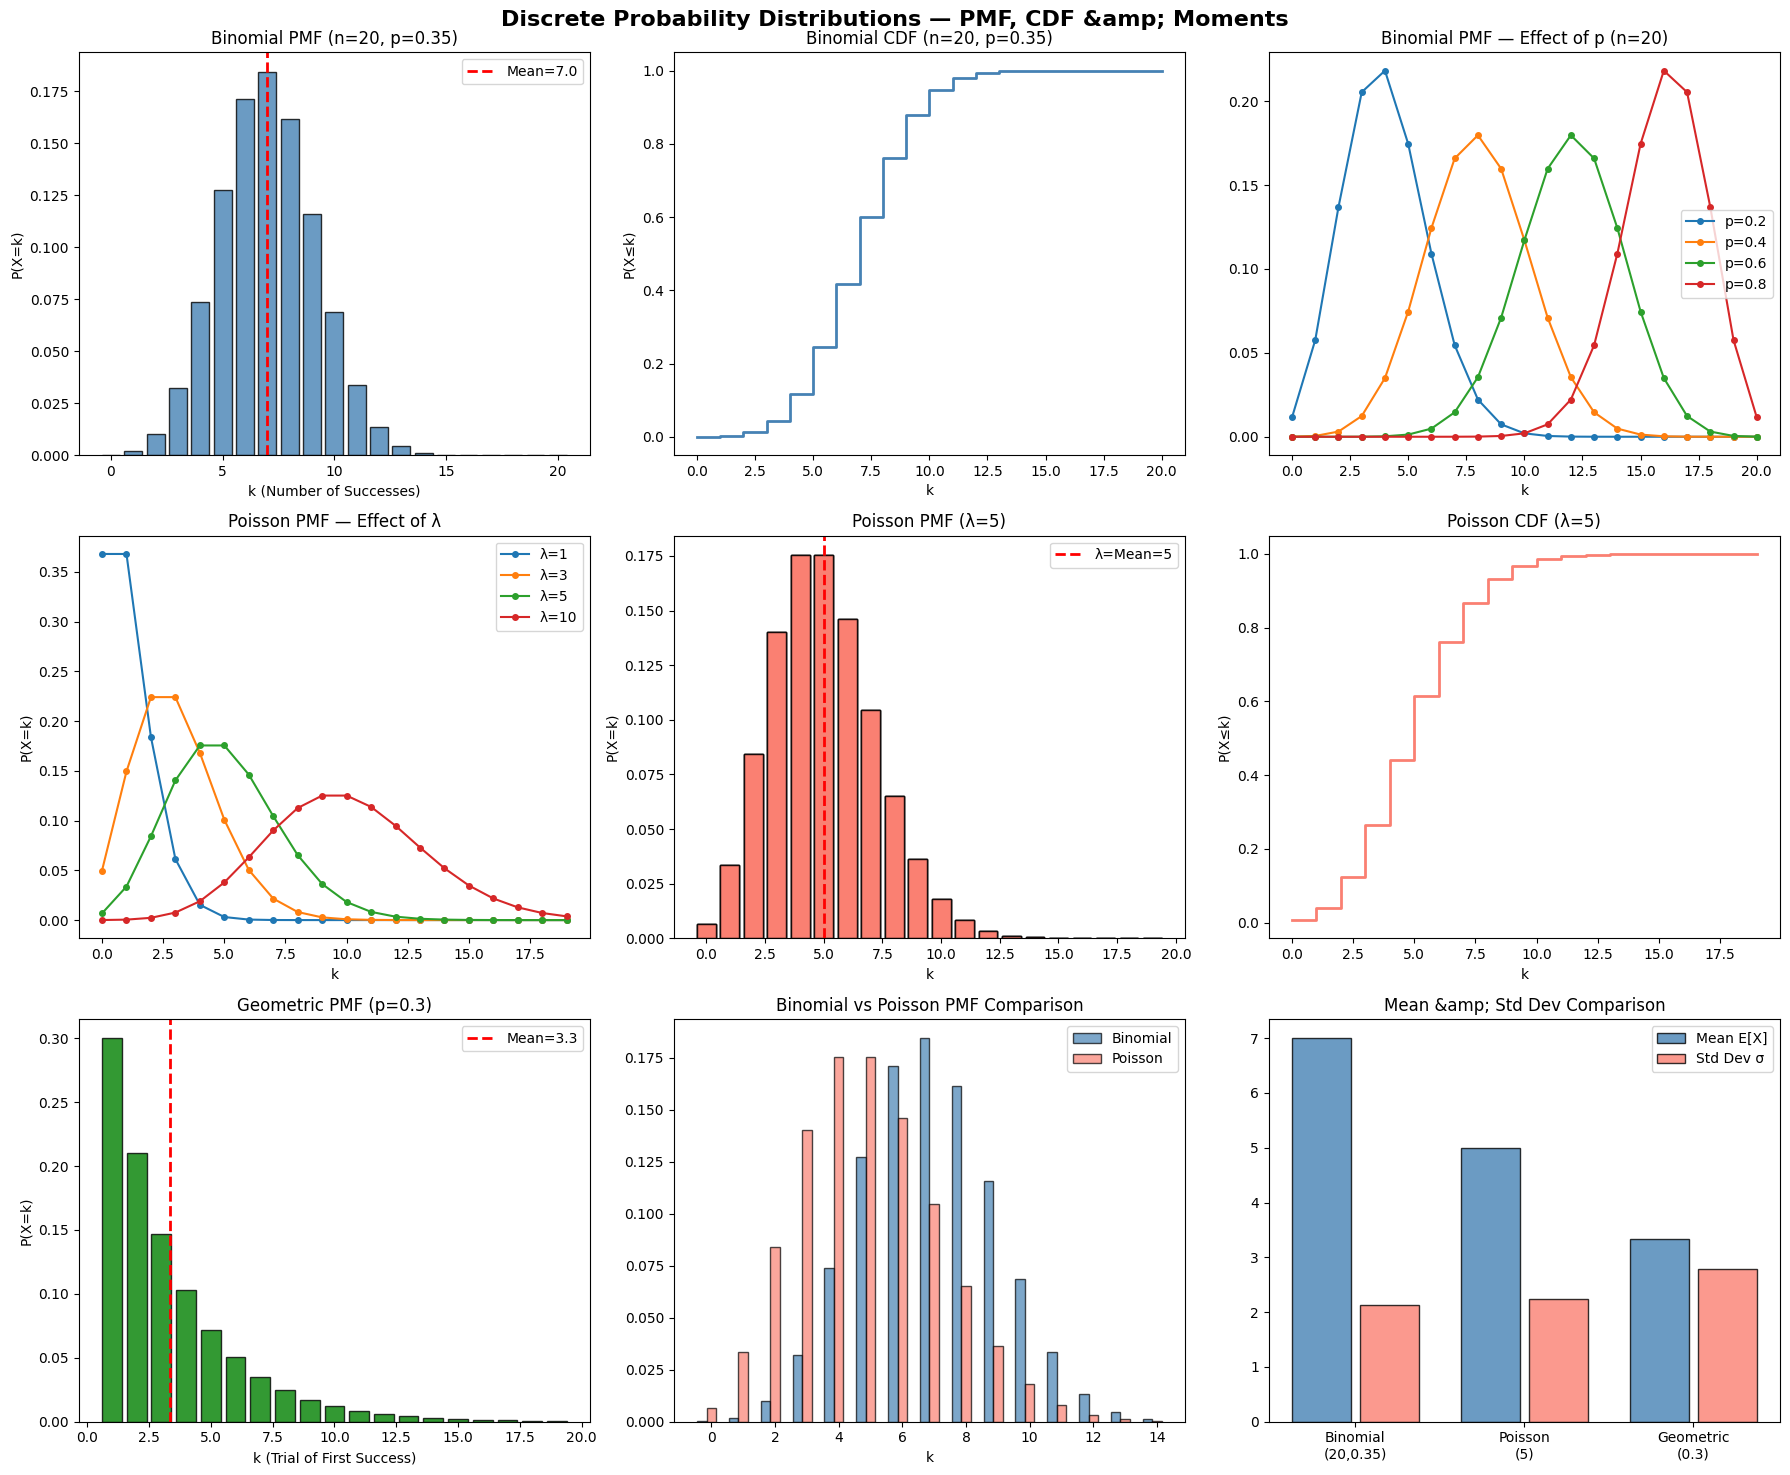


Program 2 Completed Successfully.


In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(18, 15))
fig.suptitle('Discrete Probability Distributions — PMF, CDF &amp; Moments',
fontsize=16, fontweight='bold')
# Row 1: Binomial
axes[0, 0].bar(x_binom, binom_dist.pmf(x_binom),
color='steelblue', edgecolor='black', alpha=0.8)
axes[0, 0].axvline(binom_dist.mean(), color='red',
linestyle='--', linewidth=2,
label=f'Mean={binom_dist.mean():.1f}')
axes[0, 0].set_title(f'Binomial PMF (n={n}, p={p})')
axes[0, 0].set_xlabel('k (Number of Successes)')
axes[0, 0].set_ylabel('P(X=k)')
axes[0, 0].legend()
axes[0, 1].step(x_binom, binom_dist.cdf(x_binom),
color='steelblue', linewidth=2, where='post')
axes[0, 1].set_title(f'Binomial CDF (n={n}, p={p})')
axes[0, 1].set_xlabel('k')
axes[0, 1].set_ylabel('P(X≤k)')
# Effect of p on Binomial
for p_val in [0.2, 0.4, 0.6, 0.8]:
  axes[0, 2].plot(x_binom, stats.binom.pmf(x_binom, 20, p_val),
  marker='o', markersize=4,
  label=f'p={p_val}', linewidth=1.5)
  axes[0, 2].set_title('Binomial PMF — Effect of p (n=20)')
  axes[0, 2].set_xlabel('k')
  axes[0, 2].legend()

# Row 2: Poisson
for lam in lambdas:
  axes[1, 0].plot(x_pois, stats.poisson.pmf(x_pois, lam),
  marker='o', markersize=4,
  label=f'λ={lam}', linewidth=1.5)
  axes[1, 0].set_title('Poisson PMF — Effect of λ')
  axes[1, 0].set_xlabel('k')
  axes[1, 0].set_ylabel('P(X=k)')
  axes[1, 0].legend()
  axes[1, 1].bar(x_pois, pois_main.pmf(x_pois),
color='salmon', edgecolor='black', alpha=0.8)
axes[1, 1].axvline(lam_main, color='red', linestyle='--',
linewidth=2, label=f'λ=Mean={lam_main}')
axes[1, 1].set_title(f'Poisson PMF (λ={lam_main})')
axes[1, 1].set_xlabel('k')
axes[1, 1].set_ylabel('P(X=k)')
axes[1, 1].legend()
axes[1, 2].step(x_pois, pois_main.cdf(x_pois),
color='salmon', linewidth=2, where='post')
axes[1, 2].set_title(f'Poisson CDF (λ={lam_main})')
axes[1, 2].set_xlabel('k')
axes[1, 2].set_ylabel('P(X≤k)')
# Row 3: Geometric &amp; Moments
axes[2, 0].bar(x_geo, geo_dist.pmf(x_geo),
color='green', edgecolor='black', alpha=0.8)
axes[2, 0].axvline(geo_dist.mean(), color='red',
linestyle='--', linewidth=2,
label=f'Mean={geo_dist.mean():.1f}')
axes[2, 0].set_title(f'Geometric PMF (p={p_geo})')
axes[2, 0].set_xlabel('k (Trial of First Success)')
axes[2, 0].set_ylabel('P(X=k)')
axes[2, 0].legend()
# Comparison — All Three PMFs
axes[2, 1].bar(x_binom[:15] - 0.3,
binom_dist.pmf(x_binom[:15]),
width=0.3, label='Binomial', alpha=0.7,
color='steelblue', edgecolor='black')
axes[2, 1].bar(x_pois[:15],
pois_main.pmf(x_pois[:15]),
width=0.3, label='Poisson', alpha=0.7,
color='salmon', edgecolor='black')
axes[2, 1].set_title('Binomial vs Poisson PMF Comparison')
axes[2, 1].set_xlabel('k')
axes[2, 1].legend()

# Moments Table Visualization
dist_names = ['Binomial\n(20,0.35)', 'Poisson\n(5)', 'Geometric\n(0.3)']
means = [binom_dist.mean(), pois_main.mean(), geo_dist.mean()]
stdevs = [binom_dist.std(), pois_main.std(), geo_dist.std()]
x_pos = np.arange(len(dist_names))
axes[2, 2].bar(x_pos - 0.2, means, width=0.35,
label='Mean E[X]', color='steelblue',
edgecolor='black', alpha=0.8)
axes[2, 2].bar(x_pos + 0.2, stdevs, width=0.35,
label='Std Dev σ', color='salmon',
edgecolor='black', alpha=0.8)
axes[2, 2].set_xticks(x_pos)
axes[2, 2].set_xticklabels(dist_names)
axes[2, 2].set_title('Mean &amp; Std Dev Comparison')
axes[2, 2].legend()
plt.tight_layout()
plt.savefig('P2_discrete_distributions.png', dpi=150,
bbox_inches='tight')
plt.show()
print("\nProgram 2 Completed Successfully.")